# Notebook 06 — Correct FID + E_age for the final BAP2

This notebook keeps two evaluations properly separate:

1. **FID**: computed by comparing real child images against images generated at the **child's estimated real age**. Target ages such as 5, 15, 25, 40, 60 are not mixed in.
2. **E_age**: computed on the already generated multi-age images, comparing the estimated age of each image against the prompt's target age.

Expected model:
- BAP2 final `step4689`
- NoGate / fixed alpha=0.5

Main outputs:
- CSVs with images generated at the real age for FID
- FID per method
- E_age per method and age
- Thesis-ready tables


In [60]:
# ============================================================
# Cell 1 — Install dependencies
# ============================================================

import sys, subprocess, os

def pip_install(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs, check=True)

# Original pipeline dependencies
pip_install([
    "diffusers==0.27.2",
    "transformers==4.39.3",
    "accelerate",
    "safetensors",
    "huggingface_hub==0.23.0",
    "peft==0.10.0",
    "torchmetrics",
    "torch-fidelity",
])

# IP-Adapter oficial
if not os.path.exists("/content/IP-Adapter"):
    !git clone -q https://github.com/tencent-ailab/IP-Adapter.git /content/IP-Adapter

if "/content/IP-Adapter" not in sys.path:
    sys.path.append("/content/IP-Adapter")

print("✓ Dependencias listas")


✓ Dependencias listas


## Common setup


In [ ]:
# === Common project bootstrap ===
# Bootstrap Colab/Drive + src path
import os, sys

DRIVE = "/content/drive/MyDrive/Notebook4"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

for _path in [DRIVE, "/content", "/content/IP-Adapter"]:
    if _path not in sys.path:
        sys.path.insert(0, _path)


from src.config import DEFAULT_DRIVE
from src.inference_utils import (
    CHILD_NEGATIVE_PROMPT,
    DEFAULT_NEGATIVE_PROMPT,
    collect_bap2_alpha_stats,
    ensure_2d,
    generate_bap2_image,
    get_embedding,
    set_parent_scale_bap2,
)

from src.notebook_setup import setup_full_generation_context
from src.inference_utils import make_arcface_embedder

DRIVE = globals().get("DRIVE", DEFAULT_DRIVE)
ctx = setup_full_generation_context(
    DRIVE,
    load_data=True,
    load_arcface=True,
    parent_scale=0.1,
)

paths = ctx.paths
runtime = ctx.runtime
data = ctx.data
pipe = ctx.pipe
ip_model = ctx.ip_model
bap2_modules = ctx.bap2_modules
arcface_torch = ctx.arcface_torch

DEVICE = runtime.device
DTYPE = runtime.dtype
FIW_ROOT = str(paths.fiw_root)
EMBEDDINGS_PATH = str(paths.embeddings_path)
TEST_CSV = str(paths.test_csv)
FINAL_TEST_DIR = f"{DRIVE}/results/eval"

embeddings = data.embeddings
gender_dict = data.gender_dict
test_ds = data.test_ds
test_loader = data.test_loader
arcface_embed_from_pil = make_arcface_embedder(arcface_torch, DEVICE)

print('Metrics context ready')
print('BAP2 modules:', len(bap2_modules))


# Helpers cuantitativos comunes
import torch

gate_state = ctx.checkpoint["bap2_gate_state"]
current_keys = list(bap2_modules.keys())
ckpt_keys = list(gate_state.keys())
GUIDANCE = globals().get("GUIDANCE", 4.0)
STEPS = globals().get("STEPS", 30)
NEGATIVE_PROMPT = globals().get("NEGATIVE_PROMPT", DEFAULT_NEGATIVE_PROMPT)

def get_emb(key):
    return get_embedding(embeddings, key)

def reset_gate_to_nogate():
    for _name, proc in bap2_modules.items():
        proc.gate.float()
        with torch.no_grad():
            proc.gate.weight.zero_()
            proc.gate.bias.zero_()
        proc.gate.to(DEVICE)

def reload_bap2_gate_checkpoint():
    for _name, proc in bap2_modules.items():
        if _name in gate_state:
            proc.gate.load_state_dict(gate_state[_name])
        else:
            break
    else:
        return
    for current_name, ckpt_name in zip(current_keys, ckpt_keys):
        bap2_modules[current_name].gate.load_state_dict(gate_state[ckpt_name])

def key_to_path(key):
    path = os.path.join(FIW_ROOT, str(key))
    assert os.path.exists(path), f"Image does not exist: {path}"
    return path

def rounded_age(x):
    return max(1, int(round(float(x))))

@torch.inference_mode()
def generate_bap2_quantitative(h_c, h_p, h_m, gender, age, seed, parent_scale=0.1):
    img, prompt, _alpha_stats = generate_bap2_image(
        pipe=pipe,
        ip_model=ip_model,
        h_c=h_c,
        h_p=h_p,
        h_m=h_m,
        gender=gender,
        age=age,
        device=DEVICE,
        dtype=DTYPE,
        parent_scale=parent_scale,
        seed=seed,
        guidance_scale=GUIDANCE,
        num_inference_steps=STEPS,
        negative_prompt=NEGATIVE_PROMPT,
        child_prompt=False,
    )
    return img, prompt

print('Helpers cuantitativos listos')


In [ ]:
# ============================================================
# Cell 7 — Copy real child images for FID
# ============================================================

real_rows = []

for triad_idx in range(len(test_ds)):
    sample = test_ds[triad_idx]
    key_c = sample["key_c"]
    src = key_to_path(key_c)
    dst = f"{REAL_CHILD_FID_DIR}/triad_{triad_idx:04d}_real_child.jpg"

    # Save an RGB-normalized copy to avoid read issues
    if not os.path.exists(dst):
        Image.open(src).convert("RGB").save(dst, quality=95)

    real_rows.append({
        "triad_idx": triad_idx,
        "key_c": key_c,
        "real_age_child": float(sample["age"]),
        "real_child_path": dst,
    })

df_real_fid = pd.DataFrame(real_rows)
REAL_FID_CSV = f"{OUT_DIR}/df_real_for_fid.csv"
df_real_fid.to_csv(REAL_FID_CSV, index=False)

print("Real children:", len(df_real_fid))
print("Folder:", REAL_CHILD_FID_DIR)
print("CSV:", REAL_FID_CSV)
display(df_real_fid.head())


Real children: 208
Carpeta: /content/drive/MyDrive/Notebook4/results/eval/real_age/real
CSV: /content/drive/MyDrive/Notebook4/results/eval/fid_age/df_real_for_fid.csv


,triad_idx,key_c,real_age_child,real_child_path
0,0,F0003/MID1/P00019_face1.jpg,43.0,/content/drive/MyDrive/Notebook4/results/final...
1,1,F0003/MID4/P00023_face1.jpg,49.0,/content/drive/MyDrive/Notebook4/results/final...
2,2,F0008/MID2/P00083_face1.jpg,8.0,/content/drive/MyDrive/Notebook4/results/final...
3,3,F0008/MID3/P00083_face3.jpg,7.0,/content/drive/MyDrive/Notebook4/results/final...
4,4,F0008/MID8/P00094_face2.jpg,6.0,/content/drive/MyDrive/Notebook4/results/final...


In [68]:
# ============================================================
# Cell 8 — Generate images at the real age for FID
# Variantes:
#   1) BAP2 λ=0.0
#   2) NoGate α=0.5 λ=0.1
#   3) BAP2 λ=0.1
# ============================================================

GENERATE_BAP2_L0_REAL_AGE     = True
GENERATE_NOGATE_REAL_AGE      = True
GENERATE_BAP2_L01_REAL_AGE    = True

FORCE_REGENERATE = False

# ------------------------------------------------------------
# Directorios
# ------------------------------------------------------------

BAP2_L0_FID_DIR = (
    f"{OUT_DIR}/img_bap2_l0"
)

NOGATE_FID_DIR = (
    f"{OUT_DIR}/img_nogate"
)

BAP2_L01_FID_DIR = (
    f"{OUT_DIR}/img_bap2_l01"
)

os.makedirs(BAP2_L0_FID_DIR, exist_ok=True)
os.makedirs(NOGATE_FID_DIR, exist_ok=True)
os.makedirs(BAP2_L01_FID_DIR, exist_ok=True)

# ------------------------------------------------------------
# Generation
# ------------------------------------------------------------

def generate_real_age_set(
    method_name,
    out_dir,
    use_nogate=False,
    parent_scale=0.1,
):
    os.makedirs(out_dir, exist_ok=True)

    # --------------------------------------------------------
    # Configurar gates
    # --------------------------------------------------------

    if use_nogate:
        reset_gate_to_nogate()
        print("✓ NoGate activado: alpha=0.5")
    else:
        reload_bap2_gate_checkpoint()
        print("✓ BAP2 aprendido activado")

    rows = []

    # --------------------------------------------------------
    # Triad loop
    # --------------------------------------------------------

    for triad_idx in range(len(test_ds)):

        sample = test_ds[triad_idx]

        gender = sample.get("gender", "person")

        if gender not in ["man", "woman", "person"]:
            gender = "person"

        age_real = rounded_age(sample["age"])

        h_c = get_emb(sample["key_c"])
        h_p = get_emb(sample["key_p"])
        h_m = get_emb(sample["key_m"])

        seed = BASE_SEED + triad_idx * 1000 + age_real

        out_path = (
            f"{out_dir}/"
            f"triad_{triad_idx:04d}_"
            f"realage_{age_real:02d}_"
            f"{method_name}.jpg"
        )

        # ----------------------------------------------------
        # Skip if it already exists
        # ----------------------------------------------------

        if os.path.exists(out_path) and not FORCE_REGENERATE:

            prompt = (
                f"portrait photo of a {gender}, "
                f"age {age_real}, realistic, neutral expression"
            )

            print(
                f"skip {method_name} "
                f"triad={triad_idx} "
                f"age_real={age_real}"
            )

        else:

            img, prompt = generate_bap2_quantitative(
                h_c=h_c,
                h_p=h_p,
                h_m=h_m,
                gender=gender,
                age=age_real,
                seed=seed,
                parent_scale=parent_scale,
            )

            img.save(out_path, quality=95)

            print(
                f"✓ {method_name} "
                f"{triad_idx+1}/{len(test_ds)} "
                f"age_real={age_real}"
            )

        # ----------------------------------------------------
        # Row
        # ----------------------------------------------------

        rows.append({
            "variant": method_name,
            "triad_idx": triad_idx,
            "target_age_for_fid": age_real,
            "real_age_child": float(sample["age"]),
            "gender": gender,
            "parent_scale": parent_scale,
            "seed": seed,
            "key_p": sample["key_p"],
            "key_m": sample["key_m"],
            "key_c": sample["key_c"],
            "image_path": out_path,
            "prompt": prompt,
        })

        # ----------------------------------------------------
        # Incremental saving
        # ----------------------------------------------------

        pd.DataFrame(rows).to_csv(
            f"{out_dir}/df_{method_name}_real_age_for_fid.csv",
            index=False
        )

    # --------------------------------------------------------
    # CSV final
    # --------------------------------------------------------

    df = pd.DataFrame(rows)

    csv_path = (
        f"{out_dir}/"
        f"df_{method_name}_real_age_for_fid.csv"
    )

    df.to_csv(csv_path, index=False)

    print("✓ CSV:", csv_path)

    return df

# ============================================================
# 1) BAP2 λ=0.0
# ============================================================

if GENERATE_BAP2_L0_REAL_AGE:

    df_bap2_l0_fid = generate_real_age_set(
        method_name="BAP2_lambda0",
        out_dir=BAP2_L0_FID_DIR,
        use_nogate=False,
        parent_scale=0.0,
    )

else:

    df_bap2_l0_fid = pd.read_csv(
        f"{BAP2_L0_FID_DIR}/"
        f"df_BAP2_lambda0_real_age_for_fid.csv"
    )

# ============================================================
# 2) NoGate α=0.5 λ=0.1
# ============================================================

if GENERATE_NOGATE_REAL_AGE:

    df_nogate_fid = generate_real_age_set(
        method_name="NoGate_alpha05",
        out_dir=NOGATE_FID_DIR,
        use_nogate=True,
        parent_scale=0.1,
    )

else:

    df_nogate_fid = pd.read_csv(
        f"{NOGATE_FID_DIR}/"
        f"df_NoGate_alpha05_real_age_for_fid.csv"
    )

# ============================================================
# 3) BAP2 λ=0.1
# ============================================================

if GENERATE_BAP2_L01_REAL_AGE:

    df_bap2_l01_fid = generate_real_age_set(
        method_name="BAP2_lambda01",
        out_dir=BAP2_L01_FID_DIR,
        use_nogate=False,
        parent_scale=0.1,
    )

else:

    df_bap2_l01_fid = pd.read_csv(
        f"{BAP2_L01_FID_DIR}/"
        f"df_BAP2_lambda01_real_age_for_fid.csv"
    )

# ============================================================
# Restaurar BAP2 aprendido
# ============================================================

reload_bap2_gate_checkpoint()

# ============================================================
# Summary
# ============================================================

print("\n==============================")
print("FID generation summary")
print("==============================")

print("BAP2 λ=0.0:", len(df_bap2_l0_fid))
print("NoGate α=0.5:", len(df_nogate_fid))
print("BAP2 λ=0.1:", len(df_bap2_l01_fid))

display(df_bap2_l0_fid.head())
display(df_nogate_fid.head())
display(df_bap2_l01_fid.head())

✓ BAP2 aprendido activado


  0%|          | 0/30 [00:00<?, ?it/s]

✓ BAP2_lambda0 1/208 age_real=43


  0%|          | 0/30 [00:00<?, ?it/s]

✓ BAP2_lambda0 2/208 age_real=49


...

  0%|          | 0/30 [00:00<?, ?it/s]

✓ BAP2_lambda01 208/208 age_real=8
✓ CSV: /content/drive/MyDrive/Notebook4/results/eval/fid_age/img_bap2_l01/df_BAP2_lambda01_real_age_for_fid.csv

FID generation summary
BAP2 λ=0.0: 208
NoGate α=0.5: 208
BAP2 λ=0.1: 208


,variant,triad_idx,target_age_for_fid,real_age_child,gender,parent_scale,seed,key_p,key_m,key_c,image_path,prompt
0,BAP2_lambda0,0,43,43.0,woman,0.0,85,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 43, realistic, ..."
1,BAP2_lambda0,1,49,49.0,woman,0.0,1091,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID4/P00023_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 49, realistic, ..."
2,BAP2_lambda0,2,8,8.0,woman,0.0,2050,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID2/P00083_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 8, realistic, n..."
3,BAP2_lambda0,3,7,7.0,woman,0.0,3049,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID3/P00083_face3.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 7, realistic, n..."
4,BAP2_lambda0,4,6,6.0,man,0.0,4048,F0008/MID4/P00084_face1.jpg,F0008/MID9/P00095_face2.jpg,F0008/MID8/P00094_face2.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a man, age 6, realistic, neu..."


,variant,triad_idx,target_age_for_fid,real_age_child,gender,parent_scale,seed,key_p,key_m,key_c,image_path,prompt
0,NoGate_alpha05,0,43,43.0,woman,0.1,85,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 43, realistic, ..."
1,NoGate_alpha05,1,49,49.0,woman,0.1,1091,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID4/P00023_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 49, realistic, ..."
2,NoGate_alpha05,2,8,8.0,woman,0.1,2050,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID2/P00083_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 8, realistic, n..."
3,NoGate_alpha05,3,7,7.0,woman,0.1,3049,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID3/P00083_face3.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 7, realistic, n..."
4,NoGate_alpha05,4,6,6.0,man,0.1,4048,F0008/MID4/P00084_face1.jpg,F0008/MID9/P00095_face2.jpg,F0008/MID8/P00094_face2.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a man, age 6, realistic, neu..."


,variant,triad_idx,target_age_for_fid,real_age_child,gender,parent_scale,seed,key_p,key_m,key_c,image_path,prompt
0,BAP2_lambda01,0,43,43.0,woman,0.1,85,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 43, realistic, ..."
1,BAP2_lambda01,1,49,49.0,woman,0.1,1091,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID4/P00023_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 49, realistic, ..."
2,BAP2_lambda01,2,8,8.0,woman,0.1,2050,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID2/P00083_face1.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 8, realistic, n..."
3,BAP2_lambda01,3,7,7.0,woman,0.1,3049,F0008/MID1/P00083_face2.jpg,F0008/MID7/P00091_face1.jpg,F0008/MID3/P00083_face3.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a woman, age 7, realistic, n..."
4,BAP2_lambda01,4,6,6.0,man,0.1,4048,F0008/MID4/P00084_face1.jpg,F0008/MID9/P00095_face2.jpg,F0008/MID8/P00094_face2.jpg,/content/drive/MyDrive/Notebook4/results/final...,"portrait photo of a man, age 6, realistic, neu..."


In [69]:
import os, pandas as pd

for d in [BAP2_L0_FID_DIR, NOGATE_FID_DIR, BAP2_L01_FID_DIR]:
    csvs = [f for f in os.listdir(d) if f.endswith(".csv")]
    print("\nDIR:", d)
    print("CSVs:", csvs)
    for c in csvs:
        path = os.path.join(d, c)
        df = pd.read_csv(path)
        print(c, "rows:", len(df), "triads:", df["triad_idx"].nunique())


DIR: /content/drive/MyDrive/Notebook4/results/eval/fid_age/img_bap2_l0
CSVs: ['df_BAP2_lambda0_real_age_for_fid.csv']
df_BAP2_lambda0_real_age_for_fid.csv rows: 208 triads: 208

DIR: /content/drive/MyDrive/Notebook4/results/eval/fid_age/img_nogate
CSVs: ['df_NoGate_alpha05_real_age_for_fid.csv']
df_NoGate_alpha05_real_age_for_fid.csv rows: 208 triads: 208

DIR: /content/drive/MyDrive/Notebook4/results/eval/fid_age/img_bap2_l01
CSVs: ['df_BAP2_lambda01_real_age_for_fid.csv']
df_BAP2_lambda01_real_age_for_fid.csv rows: 208 triads: 208


In [77]:
# ============================================================
# Cell 9 — Create FID-ready folders with a fixed 512x512 size
# ============================================================

import os
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import pandas as pd

FID_SIZE = 512

FID_READY_DIR = f"{OUT_DIR}/fid_ready_{FID_SIZE}"

REAL_CHILD_FID_READY_DIR = f"{FID_READY_DIR}/real"
BAP2_L0_FID_READY_DIR    = f"{FID_READY_DIR}/bap2_l0"
NOGATE_FID_READY_DIR     = f"{FID_READY_DIR}/nogate"
BAP2_L01_FID_READY_DIR   = f"{FID_READY_DIR}/bap2_l01"

for d in [
    REAL_CHILD_FID_READY_DIR,
    BAP2_L0_FID_READY_DIR,
    NOGATE_FID_READY_DIR,
    BAP2_L01_FID_READY_DIR,
]:
    os.makedirs(d, exist_ok=True)


def make_fid_ready_from_csv(df, src_col, out_dir, prefix):
    rows = []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=prefix):
        triad_idx = int(row["triad_idx"])
        src_path = str(row[src_col])

        assert os.path.exists(src_path), f"Does not exist: {src_path}"

        dst_path = f"{out_dir}/{prefix}_triad_{triad_idx:04d}.jpg"

        if not os.path.exists(dst_path):
            img = Image.open(src_path).convert("RGB")
            img = ImageOps.fit(
                img,
                (FID_SIZE, FID_SIZE),
                method=Image.Resampling.LANCZOS,
                centering=(0.5, 0.5),
            )
            img.save(dst_path, quality=95)

        rows.append({
            "triad_idx": triad_idx,
            "source_path": src_path,
            "fid_ready_path": dst_path,
        })

    return pd.DataFrame(rows)


df_real_ready = make_fid_ready_from_csv(
    df_real_fid,
    src_col="real_child_path",
    out_dir=REAL_CHILD_FID_READY_DIR,
    prefix="real_child",
)

df_bap2_l0_ready = make_fid_ready_from_csv(
    df_bap2_l0_fid,
    src_col="image_path",
    out_dir=BAP2_L0_FID_READY_DIR,
    prefix="bap2_l0",
)

df_nogate_ready = make_fid_ready_from_csv(
    df_nogate_fid,
    src_col="image_path",
    out_dir=NOGATE_FID_READY_DIR,
    prefix="nogate",
)

df_bap2_l01_ready = make_fid_ready_from_csv(
    df_bap2_l01_fid,
    src_col="image_path",
    out_dir=BAP2_L01_FID_READY_DIR,
    prefix="bap2_l01",
)

df_real_ready.to_csv(f"{FID_READY_DIR}/manifest_real.csv", index=False)
df_bap2_l0_ready.to_csv(f"{FID_READY_DIR}/manifest_bap2_l0.csv", index=False)
df_nogate_ready.to_csv(f"{FID_READY_DIR}/manifest_nogate.csv", index=False)
df_bap2_l01_ready.to_csv(f"{FID_READY_DIR}/manifest_bap2_l01.csv", index=False)

print("FID_READY_DIR:", FID_READY_DIR)
print("real:", len(os.listdir(REAL_CHILD_FID_READY_DIR)))
print("bap2 λ=0:", len(os.listdir(BAP2_L0_FID_READY_DIR)))
print("nogate:", len(os.listdir(NOGATE_FID_READY_DIR)))
print("bap2 λ=0.1:", len(os.listdir(BAP2_L01_FID_READY_DIR)))

assert len(os.listdir(REAL_CHILD_FID_READY_DIR)) == 208
assert len(os.listdir(BAP2_L0_FID_READY_DIR)) == 208
assert len(os.listdir(NOGATE_FID_READY_DIR)) == 208
assert len(os.listdir(BAP2_L01_FID_READY_DIR)) == 208

real_child:   0%|          | 0/208 [00:00<?, ?it/s]

bap2_l0:   0%|          | 0/208 [00:00<?, ?it/s]

nogate:   0%|          | 0/208 [00:00<?, ?it/s]

bap2_l01:   0%|          | 0/208 [00:00<?, ?it/s]

FID_READY_DIR: /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready
real: 208
bap2 λ=0: 208
nogate: 208
bap2 λ=0.1: 208


In [78]:
# ============================================================
# Cell 10 — Compute FID for the 3 variants using FID-ready
# ============================================================

import os
import sys
import subprocess
import pandas as pd
import torch

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "pytorch-fid"],
    check=True
)

from pytorch_fid.fid_score import calculate_fid_given_paths

FID_BATCH_SIZE = 16
FID_DIMS = 2048
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

fid_variants = [
    {
        "variant": "BAP2_lambda0",
        "gen_dir": BAP2_L0_FID_READY_DIR,
        "description": "BAP2 with parent_scale=0.0",
    },
    {
        "variant": "NoGate_alpha05",
        "gen_dir": NOGATE_FID_READY_DIR,
        "description": "BAP2 NoGate fixed alpha=0.5, parent_scale=0.1",
    },
    {
        "variant": "BAP2_lambda01",
        "gen_dir": BAP2_L01_FID_READY_DIR,
        "description": "BAP2 learned gate, parent_scale=0.1",
    },
]

fid_rows = []

for item in fid_variants:
    variant = item["variant"]
    gen_dir = item["gen_dir"]

    n_real = len([
        f for f in os.listdir(REAL_CHILD_FID_READY_DIR)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    n_gen = len([
        f for f in os.listdir(gen_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print("\n" + "=" * 80)
    print("Computing FID:", variant)
    print("Reales:", n_real, REAL_CHILD_FID_READY_DIR)
    print("Generadas:", n_gen, gen_dir)
    print("=" * 80)

    assert n_real == 208, f"Reales esperadas 208, hay {n_real}"
    assert n_gen == 208, f"Generadas esperadas 208, hay {n_gen}"

    fid_value = calculate_fid_given_paths(
        paths=[REAL_CHILD_FID_READY_DIR, gen_dir],
        batch_size=FID_BATCH_SIZE,
        device=FID_DEVICE,
        dims=FID_DIMS,
        num_workers=0,
    )

    fid_rows.append({
        "variant": variant,
        "FID": fid_value,
        "n_real": n_real,
        "n_generated": n_gen,
        "real_dir": REAL_CHILD_FID_READY_DIR,
        "generated_dir": gen_dir,
        "description": item["description"],
        "fid_image_size": FID_SIZE,
    })

    print(f"FID {variant}: {fid_value:.4f}")

df_fid_results = pd.DataFrame(fid_rows)

FID_RESULTS_CSV = f"{OUT_DIR}/fid_results_real_age_fid_ready_{FID_SIZE}.csv"
df_fid_results.to_csv(FID_RESULTS_CSV, index=False)

print("\n==============================")
print("FID final")
print("==============================")
display(df_fid_results)

print("✓ Saved:", FID_RESULTS_CSV)


Computing FID: BAP2_lambda0
Reales: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/real
Generadas: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/bap2_l0


100%|██████████| 13/13 [00:02<00:00,  5.31it/s]


FID BAP2_lambda0: 193.6788

Computing FID: NoGate_alpha05
Reales: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/real
Generadas: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/nogate


100%|██████████| 13/13 [00:02<00:00,  5.16it/s]


FID NoGate_alpha05: 192.8812

Computing FID: BAP2_lambda01
Reales: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/real
Generadas: 208 /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_ready/bap2_l01


100%|██████████| 13/13 [00:02<00:00,  5.82it/s]


FID BAP2_lambda01: 193.0262

FID final


,variant,FID,n_real,n_generated,real_dir,generated_dir,description,fid_image_size
0,BAP2_lambda0,193.678765,208,208,/content/drive/MyDrive/Notebook4/results/final...,/content/drive/MyDrive/Notebook4/results/final...,BAP2 with parent_scale=0.0,512
1,NoGate_alpha05,192.881203,208,208,/content/drive/MyDrive/Notebook4/results/final...,/content/drive/MyDrive/Notebook4/results/final...,"BAP2 NoGate fixed alpha=0.5, parent_scale=0.1",512
2,BAP2_lambda01,193.026238,208,208,/content/drive/MyDrive/Notebook4/results/final...,/content/drive/MyDrive/Notebook4/results/final...,"BAP2 learned gate, parent_scale=0.1",512


✓ Saved: /content/drive/MyDrive/Notebook4/results/eval/fid_age/fid_results_real_age_fid_ready.csv


In [79]:
# ============================================================
# Cell 10b — Prepare E_age on the existing multi-age images
# ============================================================

assert os.path.exists(BAP2_MULTI_CSV), BAP2_MULTI_CSV
assert os.path.exists(NOGATE_MULTI_CSV), NOGATE_MULTI_CSV

df_bap2_multi = pd.read_csv(BAP2_MULTI_CSV)
df_nogate_multi = pd.read_csv(NOGATE_MULTI_CSV)

# Use BAP2 with parent_scale 0.1 if the CSV also contains λ=0.0
df_bap2_multi = df_bap2_multi[df_bap2_multi["parent_scale"] == 0.1].copy()
df_nogate_multi = df_nogate_multi.copy()

print("BAP2 multi rows:", len(df_bap2_multi))
print("NoGate multi rows:", len(df_nogate_multi))
print("BAP2 ages:", sorted(df_bap2_multi["age"].unique()))
print("NoGate ages:", sorted(df_nogate_multi["age"].unique()))

for name, df in [("BAP2", df_bap2_multi), ("NoGate", df_nogate_multi)]:
    assert "image_path" in df.columns, f"{name} has no image_path"
    ok = df["image_path"].apply(lambda p: os.path.exists(str(p)))
    print(name, "existen:", ok.sum(), "/", len(ok), "faltan:", (~ok).sum())
    if (~ok).sum() > 0:
        display(df.loc[~ok, ["triad_idx", "age", "image_path"]].head())
    assert ok.all(), f"Missing images in {name}"

df_eage_inputs = pd.concat([
    df_bap2_multi.assign(eval_variant="BAP2_step4689"),
    df_nogate_multi.assign(eval_variant="NoGate_alpha05"),
], ignore_index=True)

EAGE_INPUT_CSV = f"{OUT_DIR}/inputs.csv"
df_eage_inputs.to_csv(EAGE_INPUT_CSV, index=False)

print("Total images for E_age:", len(df_eage_inputs))
print("CSV:", EAGE_INPUT_CSV)
display(df_eage_inputs.head())


BAP2 multi rows: 1040
NoGate multi rows: 1040
BAP2 ages: [np.int64(5), np.int64(15), np.int64(25), np.int64(40), np.int64(60)]
NoGate ages: [np.int64(5), np.int64(15), np.int64(25), np.int64(40), np.int64(60)]
BAP2 existen: 1040 / 1040 faltan: 0
NoGate existen: 1040 / 1040 faltan: 0
Total images for E_age: 2080
CSV: /content/drive/MyDrive/Notebook4/results/eval/fid_age/inputs.csv


,variant,checkpoint_step,triad_idx,age,parent_scale,gender,S_id_child,S_p_father,S_m_mother,S_family,...,alpha_std,alpha_min,alpha_max,key_p,key_m,key_c,seed,prompt,image_path,eval_variant
0,BAP2_step4689,4689,0,5,0.1,woman,0.064559,-0.008916,0.015542,0.003313,...,0.026263,0.373189,0.609731,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,47,"portrait photo of a woman, age 5, realistic, n...",/content/drive/MyDrive/Notebook4/results/final...,BAP2_step4689
1,BAP2_step4689,4689,0,15,0.1,woman,0.056055,-0.016430,-0.029264,-0.022847,...,0.026402,0.374873,0.616119,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,57,"portrait photo of a woman, age 15, realistic, ...",/content/drive/MyDrive/Notebook4/results/final...,BAP2_step4689
2,BAP2_step4689,4689,0,25,0.1,woman,0.024596,-0.005015,-0.017536,-0.011276,...,0.026794,0.372074,0.608903,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,67,"portrait photo of a woman, age 25, realistic, ...",/content/drive/MyDrive/Notebook4/results/final...,BAP2_step4689
3,BAP2_step4689,4689,0,40,0.1,woman,0.266188,0.019643,0.005054,0.012349,...,0.027771,0.367425,0.622984,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,82,"portrait photo of a woman, age 40, realistic, ...",/content/drive/MyDrive/Notebook4/results/final...,BAP2_step4689
4,BAP2_step4689,4689,0,60,0.1,woman,0.180496,-0.101078,-0.027804,-0.064441,...,0.027659,0.364907,0.613310,F0003/MID2/P00019_face2.jpg,F0003/MID3/P00022_face1.jpg,F0003/MID1/P00019_face1.jpg,102,"portrait photo of a woman, age 60, realistic, ...",/content/drive/MyDrive/Notebook4/results/final...,BAP2_step4689


## Note on E_age

The next cell originally used **DeepFace** as a practical age estimator; the final run uses **DEX** (cell 11). If you prefer another estimator such as MiVOLO, replace the estimation function with your own.

What matters is to state explicitly which estimator was used for `E_age`.

In [81]:
# ============================================================
# Cell 11 — Install and load DEX for age estimation
# ============================================================

import os
import sys
import subprocess

def pip_install(pkgs):
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q"] + pkgs,
        check=True
    )

# DEX necesita OpenCV
pip_install(["opencv-python"])

# PyTorch implementation of DEX
DEX_REPO = "/content/pytorch-DEX"

if not os.path.exists(DEX_REPO):
    subprocess.run(
        ["git", "clone", "-q", "https://github.com/siriusdemon/pytorch-DEX.git", DEX_REPO],
        check=True
    )

# Instalar como paquete local
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", DEX_REPO],
    check=True
)

import dex

# Sanity check with a real image
test_img_path = df_real_fid.iloc[0]["real_child_path"]
age_pred, female_prob, male_prob = dex.estimate(test_img_path)

print("✓ DEX ready")
print("Test image:", test_img_path)
print("Estimated age:", age_pred)
print("P(female):", female_prob)
print("P(male):", male_prob)

✓ DEX ready
Imagen prueba: /content/drive/MyDrive/Notebook4/results/eval/real_age/real/t0000.jpg
Edad estimada: 23.621262
P(female): 0.98558515
P(male): 0.014414879


In [82]:
# ============================================================
# Cell 12 — Compute E_age
# E_age = |edad_estimada - edad_objetivo|
# ============================================================

EAGE_CSV = f"{OUT_DIR}/dex.csv"

rows = []
done = set()

if os.path.exists(EAGE_CSV):
    old = pd.read_csv(EAGE_CSV)
    rows = old.to_dict("records")
    done = set(zip(old["eval_variant"], old["triad_idx"], old["age"]))
    print("Resume E_age:", len(rows), "rows")

def estimate_age_dex(path):
    age_pred, female_prob, male_prob = dex.estimate(str(path))
    return float(age_pred)

for i, row in df_eage_inputs.iterrows():
    key = (row["eval_variant"], int(row["triad_idx"]), int(row["age"]))
    if key in done:
        continue

    img_path = str(row["image_path"])
    target_age = float(row["age"])

    try:
        pred_age = estimate_age_dex(img_path)
        abs_error = abs(pred_age - target_age)
        error = None
    except Exception as e:
        pred_age = np.nan
        abs_error = np.nan
        error = str(e)

    out = row.to_dict()
    out.update({
        "age_estimator": "DEX",
        "pred_age": pred_age,
        "E_age": abs_error,
        "age_error_msg": error,
    })

    rows.append(out)

    if (len(rows) % 25) == 0:
        pd.DataFrame(rows).to_csv(EAGE_CSV, index=False)
        print("Guardadas rows:", len(rows))

# Final save
df_eage = pd.DataFrame(rows)
df_eage.to_csv(EAGE_CSV, index=False)

print("✓ E_age calculado")
print("CSV:", EAGE_CSV)
print("Filas:", len(df_eage))
print("Errores:", df_eage["age_error_msg"].notna().sum())
display(df_eage[["eval_variant", "triad_idx", "age", "pred_age", "E_age", "image_path"]].head())


Guardadas rows: 25
Guardadas rows: 50
Guardadas rows: 75
Guardadas rows: 100
Guardadas rows: 125
Guardadas rows: 150
Guardadas rows: 175
Guardadas rows: 200
Guardadas rows: 225
Guardadas rows: 250
Guardadas rows: 275
Guardadas rows: 300
Guardadas rows: 325
Guardadas rows: 350
Guardadas rows: 375
Guardadas rows: 400
Guardadas rows: 425
Guardadas rows: 450
Guardadas rows: 475
Guardadas rows: 500
Guardadas rows: 525
Guardadas rows: 550
Guardadas rows: 575
Guardadas rows: 600
Guardadas rows: 625
Guardadas rows: 650
Guardadas rows: 675
Guardadas rows: 700
Guardadas rows: 725
Guardadas rows: 750
Guardadas rows: 775
Guardadas rows: 800
Guardadas rows: 825
Guardadas rows: 850
Guardadas rows: 875
Guardadas rows: 900
Guardadas rows: 925
Guardadas rows: 950
Guardadas rows: 975
Guardadas rows: 1000
Guardadas rows: 1025
Guardadas rows: 1050
Guardadas rows: 1075
Guardadas rows: 1100
Guardadas rows: 1125
Guardadas rows: 1150
Guardadas rows: 1175
Guardadas rows: 1200
Guardadas rows: 1225
Guardadas row

,eval_variant,triad_idx,age,pred_age,E_age,image_path
0,BAP2_step4689,0,5,11.857042,6.857042,/content/drive/MyDrive/Notebook4/results/final...
1,BAP2_step4689,0,15,18.406219,3.406219,/content/drive/MyDrive/Notebook4/results/final...
2,BAP2_step4689,0,25,20.785419,4.214581,/content/drive/MyDrive/Notebook4/results/final...
3,BAP2_step4689,0,40,38.905437,1.094563,/content/drive/MyDrive/Notebook4/results/final...
4,BAP2_step4689,0,60,50.854572,9.145428,/content/drive/MyDrive/Notebook4/results/final...


In [83]:
# ============================================================
# Cell 13 — Global and per-age E_age summary
# ============================================================

df_eage_valid = df_eage.dropna(subset=["E_age"]).copy()

summary_eage_global = (
    df_eage_valid
    .groupby("eval_variant")
    .agg(
        E_age_mean=("E_age", "mean"),
        E_age_std=("E_age", "std"),
        E_age_median=("E_age", "median"),
        pred_age_mean=("pred_age", "mean"),
        n=("E_age", "count"),
    )
    .reset_index()
)

summary_eage_by_age = (
    df_eage_valid
    .groupby(["eval_variant", "age"])
    .agg(
        E_age_mean=("E_age", "mean"),
        E_age_std=("E_age", "std"),
        E_age_median=("E_age", "median"),
        pred_age_mean=("pred_age", "mean"),
        n=("E_age", "count"),
    )
    .reset_index()
)

SUMMARY_EAGE_GLOBAL_CSV = f"{OUT_DIR}/summary_global.csv"
SUMMARY_EAGE_BY_AGE_CSV = f"{OUT_DIR}/summary_age.csv"

summary_eage_global.to_csv(SUMMARY_EAGE_GLOBAL_CSV, index=False)
summary_eage_by_age.to_csv(SUMMARY_EAGE_BY_AGE_CSV, index=False)

print("==============================")
print("E_age global")
print("==============================")
display(summary_eage_global)

print("==============================")
print("E_age by age")
print("==============================")
display(summary_eage_by_age)

print("CSVs:")
print(SUMMARY_EAGE_GLOBAL_CSV)
print(SUMMARY_EAGE_BY_AGE_CSV)


E_age global


,eval_variant,E_age_mean,E_age_std,E_age_median,pred_age_mean,n
0,BAP2_step4689,7.33762,6.427712,5.760145,33.453851,1040
1,NoGate_alpha05,7.33397,6.443002,5.841691,33.450609,1040


E_age by age


,eval_variant,age,E_age_mean,E_age_std,E_age_median,pred_age_mean,n
0,BAP2_step4689,5,12.750245,7.561667,11.201345,17.750245,208
1,BAP2_step4689,15,6.544810,6.213448,5.267867,21.150157,208
2,BAP2_step4689,25,4.839123,4.656509,3.508683,27.505742,208
3,BAP2_step4689,40,7.319967,5.091096,6.458157,43.691162,208
4,BAP2_step4689,60,5.233957,4.816461,3.846771,57.171949,208
5,NoGate_alpha05,5,12.748306,7.584370,11.162331,17.748306,208
6,NoGate_alpha05,15,6.552308,6.247980,5.334735,21.145269,208
7,NoGate_alpha05,25,4.869067,4.742949,3.573011,27.555498,208
8,NoGate_alpha05,40,7.257311,5.024078,6.493196,43.661372,208
9,NoGate_alpha05,60,5.242858,4.846773,3.749857,57.142601,208


CSVs:
/content/drive/MyDrive/Notebook4/results/eval/fid_age/summary_global.csv
/content/drive/MyDrive/Notebook4/results/eval/fid_age/summary_age.csv


In [84]:
# ============================================================
# Cell 14 — Compact final table for the thesis
# Une FID + E_age
# ============================================================

# Normalize names for merging
df_fid_results = df_fid_results.copy()
df_fid_results["eval_variant"] = df_fid_results["variant"].map({
    "BAP2_step4689_real_age": "BAP2_step4689",
    "NoGate_alpha05_real_age": "NoGate_alpha05",
})

final_metrics_table = (
    summary_eage_global
    .merge(df_fid_results[["eval_variant", "FID"]], on="eval_variant", how="left")
    .sort_values("eval_variant")
    .reset_index(drop=True)
)

FINAL_TABLE_CSV = f"{OUT_DIR}/table.csv"
final_metrics_table.to_csv(FINAL_TABLE_CSV, index=False)

print("==============================")
print("Tabla final FID + E_age")
print("==============================")
display(final_metrics_table)
print("CSV:", FINAL_TABLE_CSV)


Tabla final FID + E_age


,eval_variant,E_age_mean,E_age_std,E_age_median,pred_age_mean,n,FID
0,BAP2_step4689,7.33762,6.427712,5.760145,33.453851,1040,NaN
1,NoGate_alpha05,7.33397,6.443002,5.841691,33.450609,1040,NaN


CSV: /content/drive/MyDrive/Notebook4/results/eval/fid_age/table.csv


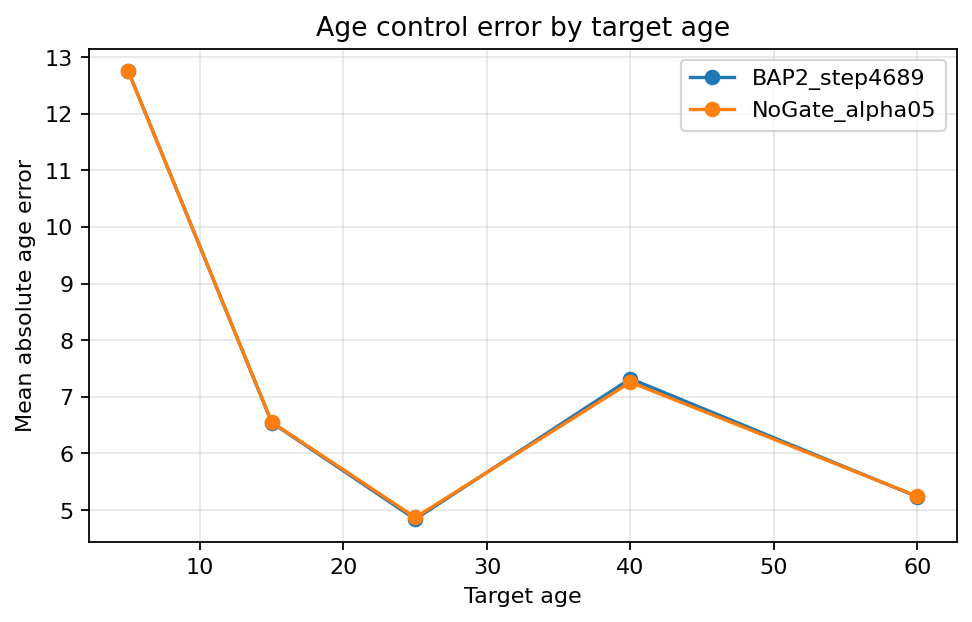

✓ Figura: /content/drive/MyDrive/Notebook4/results/eval/fid_age/age_error.png


In [85]:
# ============================================================
# Cell 15 — Simple E_age-by-age plot
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4), dpi=160)

for variant in summary_eage_by_age["eval_variant"].unique():
    sub = summary_eage_by_age[summary_eage_by_age["eval_variant"] == variant].sort_values("age")
    plt.plot(sub["age"], sub["E_age_mean"], marker="o", label=variant)

plt.xlabel("Target age")
plt.ylabel("Mean absolute age error")
plt.title("Age control error by target age")
plt.legend()
plt.grid(True, alpha=0.3)

FIG_EAGE = f"{OUT_DIR}/age_error.png"
plt.savefig(FIG_EAGE, dpi=300, bbox_inches="tight")
plt.show()

print("✓ Figura:", FIG_EAGE)


## Methodological interpretation

- **FID** is reported as visual quality/distribution under a comparable condition: real child image vs image generated at the child's estimated real age.
- **E_age** is reported as compliance with the age prompt on the multi-age generations.
- The multi-age qualitative figures are not used for FID, because mixing target ages with real children of different ages distorts the FID interpretation.


In [86]:
# ============================================================
# Main table — Identity and parental similarity
# BAP2 λ=0.0 vs NoGate α=0.5 vs BAP2 λ=0.1
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

DRIVE = "/content/drive/MyDrive/Notebook4"
FINAL_TEST_DIR = f"{DRIVE}/results/eval"

BAP2_CSV = f"{FINAL_TEST_DIR}/bap2/bap2.csv"
NOGATE_CSV = f"{FINAL_TEST_DIR}/nogate/nogate.csv"

OUT_TABLE_DIR = f"{FINAL_TEST_DIR}/tables"
os.makedirs(OUT_TABLE_DIR, exist_ok=True)

df_bap2 = pd.read_csv(BAP2_CSV)
df_nogate = pd.read_csv(NOGATE_CSV)

# Separar variantes
df_bap2_l0 = (
    df_bap2[df_bap2["parent_scale"] == 0.0]
    .copy()
    .assign(eval_variant="BAP2_lambda0")
)

df_bap2_l01 = (
    df_bap2[df_bap2["parent_scale"] == 0.1]
    .copy()
    .assign(eval_variant="BAP2_lambda01")
)

df_nogate_eval = (
    df_nogate.copy()
    .assign(eval_variant="NoGate_alpha05")
)

df_all_main = pd.concat(
    [df_bap2_l0, df_nogate_eval, df_bap2_l01],
    ignore_index=True
)

metrics = [
    "S_id_child",
    "S_p_father",
    "S_m_mother",
    "S_family",
    "balance_abs_gap",
]

# Verificaciones
print("Rows per variant:")
display(df_all_main.groupby("eval_variant").size().reset_index(name="n_rows"))

print("Triads per variant:")
display(df_all_main.groupby("eval_variant")["triad_idx"].nunique().reset_index(name="n_triads"))

print("Ages per variant:")
display(
    df_all_main
    .groupby("eval_variant")["age"]
    .apply(lambda x: sorted(x.unique()))
    .reset_index(name="ages")
)

# Global summary
summary_global = (
    df_all_main
    .groupby("eval_variant")[metrics]
    .agg(["mean", "std", "median"])
)

summary_global.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_global.columns
]

summary_global = summary_global.reset_index()

# Summary by age
summary_by_age = (
    df_all_main
    .groupby(["eval_variant", "age"])[metrics]
    .agg(["mean", "std"])
)

summary_by_age.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_by_age.columns
]

summary_by_age = summary_by_age.reset_index()

summary_global.to_csv(
    f"{OUT_TABLE_DIR}/table_identity_family_global.csv",
    index=False
)

summary_by_age.to_csv(
    f"{OUT_TABLE_DIR}/table_identity_family_by_age.csv",
    index=False
)

print("\n==============================")
print("TABLA GLOBAL IDENTIDAD / PARENTESCO")
print("==============================")
display(summary_global)

print("\n==============================")
print("TABLE BY AGE")
print("==============================")
display(summary_by_age)

print("Saved to:", OUT_TABLE_DIR)

Rows per variant:


,eval_variant,n_rows
0,BAP2_lambda0,1040
1,BAP2_lambda01,1040
2,NoGate_alpha05,1040


Triads per variant:


,eval_variant,n_triads
0,BAP2_lambda0,208
1,BAP2_lambda01,208
2,NoGate_alpha05,208


Ages per variant:


...


TABLA GLOBAL IDENTIDAD / PARENTESCO


,eval_variant,S_id_child_mean,S_id_child_std,S_id_child_median,S_p_father_mean,S_p_father_std,S_p_father_median,S_m_mother_mean,S_m_mother_std,S_m_mother_median,S_family_mean,S_family_std,S_family_median,balance_abs_gap_mean,balance_abs_gap_std,balance_abs_gap_median
0,BAP2_lambda0,0.186944,0.130109,0.178905,0.011409,0.053862,0.009883,0.017132,0.055668,0.015032,0.014271,0.040411,0.016114,0.058377,0.045711,0.048107
1,BAP2_lambda01,0.186964,0.131327,0.180365,0.017099,0.054869,0.014602,0.023106,0.055617,0.020946,0.020102,0.040908,0.019671,0.058842,0.045656,0.049370
2,NoGate_alpha05,0.186611,0.131250,0.179590,0.016898,0.054949,0.013395,0.022914,0.055820,0.021321,0.019906,0.040863,0.019964,0.059253,0.045971,0.049332



TABLA POR EDAD


,eval_variant,age,S_id_child_mean,S_id_child_std,S_p_father_mean,S_p_father_std,S_m_mother_mean,S_m_mother_std,S_family_mean,S_family_std,balance_abs_gap_mean,balance_abs_gap_std
0,BAP2_lambda0,5,0.228909,0.146985,0.015005,0.050583,0.016991,0.060875,0.015998,0.041565,0.057917,0.047451
1,BAP2_lambda0,15,0.174865,0.134578,0.009960,0.050559,0.017790,0.050613,0.013875,0.038138,0.052823,0.040935
2,BAP2_lambda0,25,0.176835,0.137633,0.006010,0.055015,0.009614,0.052639,0.007812,0.041301,0.054142,0.042887
3,BAP2_lambda0,40,0.172542,0.118526,0.008963,0.055036,0.016993,0.059410,0.012978,0.041984,0.061187,0.048673
4,BAP2_lambda0,60,0.181572,0.100031,0.017110,0.057517,0.024274,0.053649,0.020692,0.038185,0.065817,0.047322
5,BAP2_lambda01,5,0.229202,0.147585,0.021431,0.050741,0.021773,0.060193,0.021602,0.041234,0.057876,0.047213
6,BAP2_lambda01,15,0.174445,0.135177,0.014473,0.051233,0.021724,0.050687,0.018098,0.039227,0.051596,0.040132
7,BAP2_lambda01,25,0.175151,0.139827,0.011241,0.056339,0.016735,0.053032,0.013988,0.041898,0.055995,0.042791
8,BAP2_lambda01,40,0.176098,0.119578,0.015348,0.055039,0.024192,0.058450,0.019770,0.041385,0.061390,0.048292
9,BAP2_lambda01,60,0.179924,0.101998,0.023001,0.060082,0.031106,0.054726,0.027053,0.039996,0.067352,0.048153


Saved to: /content/drive/MyDrive/Notebook4/results/eval/tables


In [87]:
# ============================================================
# Table of paired deltas between variants
# ============================================================

from IPython.display import display

def paired_delta_table(df_a, name_a, df_b, name_b, metrics):
    key_cols = ["triad_idx", "age"]

    a = df_a[key_cols + metrics].copy()
    b = df_b[key_cols + metrics].copy()

    merged = a.merge(
        b,
        on=key_cols,
        suffixes=(f"_{name_a}", f"_{name_b}")
    )

    rows = []

    for m in metrics:
        d = merged[f"{m}_{name_a}"] - merged[f"{m}_{name_b}"]

        rows.append({
            "comparison": f"{name_a} - {name_b}",
            "metric": m,
            "mean_delta": d.mean(),
            "median_delta": d.median(),
            "std_delta": d.std(),
            "win_rate_a_gt_b": (d > 0).mean(),
            "n_pairs": len(d),
        })

    return pd.DataFrame(rows)

delta_01_vs_nogate = paired_delta_table(
    df_bap2_l01,
    "BAP2_lambda01",
    df_nogate_eval,
    "NoGate_alpha05",
    metrics
)

delta_01_vs_l0 = paired_delta_table(
    df_bap2_l01,
    "BAP2_lambda01",
    df_bap2_l0,
    "BAP2_lambda0",
    metrics
)

delta_nogate_vs_l0 = paired_delta_table(
    df_nogate_eval,
    "NoGate_alpha05",
    df_bap2_l0,
    "BAP2_lambda0",
    metrics
)

delta_summary = pd.concat(
    [delta_01_vs_nogate, delta_01_vs_l0, delta_nogate_vs_l0],
    ignore_index=True
)

delta_summary.to_csv(
    f"{OUT_TABLE_DIR}/table_paired_deltas.csv",
    index=False
)

print("==============================")
print("DELTAS PAREADOS")
print("==============================")
display(delta_summary)

DELTAS PAREADOS


,comparison,metric,mean_delta,median_delta,std_delta,win_rate_a_gt_b,n_pairs
0,BAP2_lambda01 - NoGate_alpha05,S_id_child,0.000353,0.000132,0.008242,0.531731,1040
1,BAP2_lambda01 - NoGate_alpha05,S_p_father,0.000200,0.000092,0.005050,0.513462,1040
2,BAP2_lambda01 - NoGate_alpha05,S_m_mother,0.000192,0.000082,0.004940,0.524038,1040
3,BAP2_lambda01 - NoGate_alpha05,S_family,0.000196,0.000087,0.003864,0.529808,1040
4,BAP2_lambda01 - NoGate_alpha05,balance_abs_gap,-0.000411,-0.000073,0.005975,0.484615,1040
5,BAP2_lambda01 - BAP2_lambda0,S_id_child,0.000020,-0.000127,0.026544,0.492308,1040
6,BAP2_lambda01 - BAP2_lambda0,S_p_father,0.005689,0.005642,0.018879,0.693269,1040
7,BAP2_lambda01 - BAP2_lambda0,S_m_mother,0.005974,0.006525,0.019555,0.700962,1040
8,BAP2_lambda01 - BAP2_lambda0,S_family,0.005831,0.005978,0.013962,0.719231,1040
9,BAP2_lambda01 - BAP2_lambda0,balance_abs_gap,0.000465,-0.000064,0.022348,0.498077,1040


In [2]:
# ============================================================
# G1 — Extract Heredity Gate alpha on TEST
# Does not generate images.
# Uses father/mother embeddings and the learned gates.
# ============================================================

import os
import torch
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from IPython.display import display

GATE_OUT_DIR = f"{DRIVE}/results/eval/gate"
os.makedirs(GATE_OUT_DIR, exist_ok=True)

assert "test_ds" in globals(), "Falta test_ds"
assert "bap2_modules" in globals(), "Falta bap2_modules"
assert "ip_model" in globals(), "Falta ip_model"
assert len(bap2_modules) == 16, "Expected 16 BAP2 modules"

pipe.unet.eval()
ip_model.image_proj_model.eval()



@torch.inference_mode()
def build_gate_input(h_p, h_m, proc):
    """
    Builds the correct input for proc.gate according to in_features.
    Soporta:
    - raw ArcFace concat: 1024
    - token mean concat: 1536
    - token flatten concat: 6144
    """
    h_p = ensure_2d(h_p).to(DEVICE, dtype=DTYPE)
    h_m = ensure_2d(h_m).to(DEVICE, dtype=DTYPE)

    in_features = proc.gate.in_features

    # 1) Raw ArcFace concat: 512 + 512 = 1024
    raw_concat = torch.cat(
        [h_p.float(), h_m.float()],
        dim=1
    )

    if raw_concat.shape[1] == in_features:
        return raw_concat

    # 2) Token features desde IP-Adapter projection
    father_tokens = ip_model.image_proj_model(h_p)
    mother_tokens = ip_model.image_proj_model(h_m)

    # Mean pooling: 768 + 768 = 1536
    token_mean_concat = torch.cat(
        [
            father_tokens.float().mean(dim=1),
            mother_tokens.float().mean(dim=1),
        ],
        dim=1
    )

    if token_mean_concat.shape[1] == in_features:
        return token_mean_concat

    # Flatten: 4*768 + 4*768 = 6144
    token_flat_concat = torch.cat(
        [
            father_tokens.float().reshape(father_tokens.shape[0], -1),
            mother_tokens.float().reshape(mother_tokens.shape[0], -1),
        ],
        dim=1
    )

    if token_flat_concat.shape[1] == in_features:
        return token_flat_concat

    raise ValueError(
        f"Could not build gate input. "
        f"in_features={in_features}, "
        f"raw={raw_concat.shape[1]}, "
        f"mean={token_mean_concat.shape[1]}, "
        f"flat={token_flat_concat.shape[1]}"
    )

rows = []

module_items = list(bap2_modules.items())

for triad_idx in tqdm(range(len(test_ds)), desc="Extrayendo alpha"):
    sample = test_ds[triad_idx]

    h_p = get_emb(sample["key_p"])
    h_m = get_emb(sample["key_m"])

    gender = sample.get("gender", "person")
    if gender not in ["man", "woman", "person"]:
        gender = "person"

    for layer_idx, (layer_name, proc) in enumerate(module_items):
        gate_input = build_gate_input(h_p, h_m, proc)

        alpha = torch.sigmoid(
            proc.gate(gate_input.to(DEVICE).float())
        ).detach().cpu().numpy()[0]

        for group_idx, a in enumerate(alpha):
            rows.append({
                "triad_idx": triad_idx,
                "gender": gender,
                "real_age_child": float(sample["age"]),
                "key_p": sample["key_p"],
                "key_m": sample["key_m"],
                "key_c": sample["key_c"],
                "layer_idx": layer_idx,
                "layer_name": layer_name,
                "group_idx": group_idx,
                "alpha": float(a),
                "alpha_centered": float(a - 0.5),
                "father_dominant": bool(a > 0.5),
            })

df_gate_alpha = pd.DataFrame(rows)

GATE_ALPHA_CSV = f"{GATE_OUT_DIR}/gate_alpha_long.csv"
df_gate_alpha.to_csv(GATE_ALPHA_CSV, index=False)

print("Filas:", len(df_gate_alpha))
print("Esperadas:", len(test_ds) * len(bap2_modules) * df_gate_alpha["group_idx"].nunique())
print("CSV:", GATE_ALPHA_CSV)

display(df_gate_alpha.head())
display(df_gate_alpha[["alpha", "alpha_centered"]].describe())


AssertionError: Falta test_ds